In [5]:

print("Bonjour ! Mon environnement Python fonctionne.")


Bonjour ! Mon environnement Python fonctionne.


In [6]:

%pip install arch pandas numpy matplotlib scipy statsmodels


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.2 MB/s  0:00:00


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

print("Installation réussie !")
print("Je peux commencer les modèles GARCH.")


Installation réussie !
Je peux commencer les modèles GARCH.


In [11]:

import pandas as pd

# Charger les données déjà importées
df = pd.read_csv("/content/spx.csv")

# Afficher les premières observations
print("Données chargées avec succès !")
print(df.head())

# Afficher les noms des colonnes
print(df.columns.tolist())

# Vérifier le nombre d'observations
print("Nombre de lignes :", len(df))


Données chargées avec succès !
         Date         open         high          low        close       ret  \
0  2000-01-04  1455.219971  1455.219971  1397.430054  1399.420044 -3.909918   
1  2000-01-05  1399.420044  1413.270020  1377.680054  1402.109985  0.192034   
2  2000-01-06  1402.109985  1411.900024  1392.099976  1403.449951  0.095522   
3  2000-01-07  1403.449951  1441.469971  1400.729980  1441.469971  2.672995   
4  2000-01-10  1441.469971  1464.359985  1441.469971  1457.599976  1.112782   

         rv        vix  
0  2.304785  27.010000  
1  3.238335  26.410000  
2  0.993764  25.730000  
3  1.349778  21.719999  
4  0.762737  21.709999  
['Date', 'open', 'high', 'low', 'close', 'ret', 'rv', 'vix']
Nombre de lignes : 6733


In [12]:

# Convertir la colonne Date en format date
df["Date"] = pd.to_datetime(df["Date"])

# Trier les observations par date
df = df.sort_values("Date")

# Sélectionner la période 2000 à 2014
df_train = df[
    (df["Date"] >= "2000-01-01") &
    (df["Date"] <= "2014-12-31")
].copy()

# Récupérer les rendements en pourcentage
rendements = df_train["ret"].dropna()

# Afficher les informations
print("Préparation terminée !")
print("Nombre d'observations :", len(rendements))
print("Première date :", df_train["Date"].min())
print("Dernière date :", df_train["Date"].max())

# Statistiques descriptives
print(rendements.describe())


Préparation terminée !
Nombre d'observations : 3772
Première date : 2000-01-04 00:00:00
Dernière date : 2014-12-31 00:00:00
count    3772.000000
mean        0.009200
std         1.283803
min        -9.469512
25%        -0.553080
50%         0.058111
75%         0.601233
max        10.957197
Name: ret, dtype: float64


In [13]:

from arch import arch_model

# Créer le modèle GARCH(1,1)
modele_garch = arch_model(
    rendements,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=0,
    q=1,
    dist="normal",
    rescale=False
)

# Estimer les paramètres
resultat_garch = modele_garch.fit(
    disp="off"
)

# Afficher les résultats
print(resultat_garch.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -5408.99
Distribution:                  Normal   AIC:                           10826.0
Method:            Maximum Likelihood   BIC:                           10850.9
                                        No. Observations:                 3772
Date:                Fri, Nov 13 2026   Df Residuals:                     3771
Time:                        01:40:59   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0488  1.393e-02      3.505  4.560e-04 [2.

In [15]:

# Récupérer les paramètres du modèle
alpha = resultat_garch.params["alpha[1]"]
beta = resultat_garch.params["beta[1]"]

# Calculer la persistance
persistance = alpha + beta

print("Alpha :", round(alpha, 4))
print("Beta :", round(beta, 4))
print("Persistance :", round(persistance, 4))

# Vérifier la stationnarité
if persistance < 1:
    print("Condition de stationnarité respectée.")
else:
    print("Attention : persistance supérieure ou égale à 1.")


Alpha : 0.0929
Beta : 0.8951
Persistance : 0.988
Condition de stationnarité respectée.


In [16]:

from arch import arch_model

# GARCH(1,1) avec loi de Student
modele_garch_student = arch_model(
    rendements,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=0,
    q=1,
    dist="t",
    rescale=False
)

# Estimer le modèle
resultat_garch_student = modele_garch_student.fit(
    disp="off"
)

# Afficher les résultats
print(resultat_garch_student.summary())


                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          ret   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5358.98
Distribution:      Standardized Student's t   AIC:                           10728.0
Method:                  Maximum Likelihood   BIC:                           10759.1
                                              No. Observations:                 3772
Date:                      Fri, Nov 13 2026   Df Residuals:                     3771
Time:                              01:43:11   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [17]:

from arch import arch_model

# Créer le modèle GJR-GARCH(1,1)
# avec la loi normale
modele_gjr_normal = arch_model(
    rendements,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="normal",
    rescale=False
)

# Estimer le modèle
resultat_gjr_normal = modele_gjr_normal.fit(
    disp="off"
)

# Afficher les résultats
print(resultat_gjr_normal.summary())

# Vérifier la convergence
print("Code de convergence :",
      resultat_gjr_normal.convergence_flag)


                   Constant Mean - GJR-GARCH Model Results                    
Dep. Variable:                    ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                  GJR-GARCH   Log-Likelihood:               -5323.27
Distribution:                  Normal   AIC:                           10656.5
Method:            Maximum Likelihood   BIC:                           10687.7
                                        No. Observations:                 3772
Date:                Fri, Nov 13 2026   Df Residuals:                     3771
Time:                        01:44:07   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         9.0183e-03  1.433e-02      0.629      0.529 

In [18]:

from arch import arch_model

# GJR-GARCH(1,1) avec loi de Student
modele_gjr_student = arch_model(
    rendements,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

# Estimer le modèle
resultat_gjr_student = modele_gjr_student.fit(
    disp="off"
)

# Afficher les résultats
print(resultat_gjr_student.summary())

# Vérifier la convergence
print("Code de convergence :",
      resultat_gjr_student.convergence_flag)

# Calculer la persistance approximative
alpha = resultat_gjr_student.params["alpha[1]"]
beta = resultat_gjr_student.params["beta[1]"]
gamma = resultat_gjr_student.params["gamma[1]"]

persistance = alpha + beta + gamma / 2

print("Persistance :", round(persistance, 4))


                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                          ret   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5288.54
Distribution:      Standardized Student's t   AIC:                           10589.1
Method:                  Maximum Likelihood   BIC:                           10626.5
                                              No. Observations:                 3772
Date:                      Fri, Nov 13 2026   Df Residuals:                     3771
Time:                              01:45:03   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [20]:

from arch import arch_model

# Créer le modèle EGARCH(1,1)
# avec asymétrie et loi normale
modele_egarch_normal = arch_model(
    rendements,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="normal",
    rescale=False
)

# Estimer le modèle
resultat_egarch_normal = modele_egarch_normal.fit(
    disp="off"
)

# Afficher les résultats
print(resultat_egarch_normal.summary())

# Vérifier la convergence
print("Code de convergence :",
      resultat_egarch_normal.convergence_flag)


                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                    ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -5318.92
Distribution:                  Normal   AIC:                           10647.8
Method:            Maximum Likelihood   BIC:                           10679.0
                                        No. Observations:                 3772
Date:                Fri, Nov 13 2026   Df Residuals:                     3771
Time:                        01:45:46   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         9.7905e-03  1.367e-02      0.716      0.474 

In [21]:

from arch import arch_model

# EGARCH(1,1) avec asymétrie
# et distribution de Student
modele_egarch_student = arch_model(
    rendements,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

# Estimer le modèle
resultat_egarch_student = modele_egarch_student.fit(
    disp="off"
)

# Afficher les résultats
print(resultat_egarch_student.summary())

# Vérifier la convergence
print("Code de convergence :",
      resultat_egarch_student.convergence_flag)


                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                          ret   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -5276.69
Distribution:      Standardized Student's t   AIC:                           10565.4
Method:                  Maximum Likelihood   BIC:                           10602.8
                                              No. Observations:                 3772
Date:                      Fri, Nov 13 2026   Df Residuals:                     3771
Time:                              01:46:59   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [22]:

import pandas as pd

# Regrouper les six modèles estimés
modeles = {
    "GARCH - Normale": resultat_garch,
    "GARCH - Student": resultat_garch_student,
    "GJR-GARCH - Normale": resultat_gjr_normal,
    "GJR-GARCH - Student": resultat_gjr_student,
    "EGARCH - Normale": resultat_egarch_normal,
    "EGARCH - Student": resultat_egarch_student
}

# Construire le tableau comparatif
comparaison = pd.DataFrame({
    nom: {
        "AIC": resultat.aic,
        "BIC": resultat.bic,
        "Log-vraisemblance": resultat.loglikelihood,
        "Convergence": resultat.convergence_flag
    }
    for nom, resultat in modeles.items()
}).T

# Classer les modèles selon leur AIC
comparaison = comparaison.sort_values("AIC")

print("COMPARAISON DES SIX MODÈLES")
display(comparaison.round(3))

print("\nMeilleur modèle selon l'AIC :")
print(comparaison.index[0])


COMPARAISON DES SIX MODÈLES


,AIC,BIC,Log-vraisemblance,Convergence
EGARCH - Student,10565.381,10602.793,-5276.690,0.0
GJR-GARCH - Student,10589.087,10626.499,-5288.543,0.0
EGARCH - Normale,10647.834,10679.011,-5318.917,0.0
GJR-GARCH - Normale,10656.540,10687.717,-5323.270,0.0
GARCH - Student,10727.950,10759.127,-5358.975,0.0
GARCH - Normale,10825.973,10850.914,-5408.986,0.0



Meilleur modèle selon l'AIC :
EGARCH - Student


TEST LJUNG-BOX : RÉSIDUS


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,lb_stat,lb_pvalue
10,26.608943,0.003002
20,39.836606,0.005238



TEST LJUNG-BOX : RÉSIDUS AU CARRÉ


,lb_stat,lb_pvalue
10,28.793979,0.001345
20,39.981052,0.005023



TEST ARCH-LM
Statistique : 28.4625
P-value : 0.001522


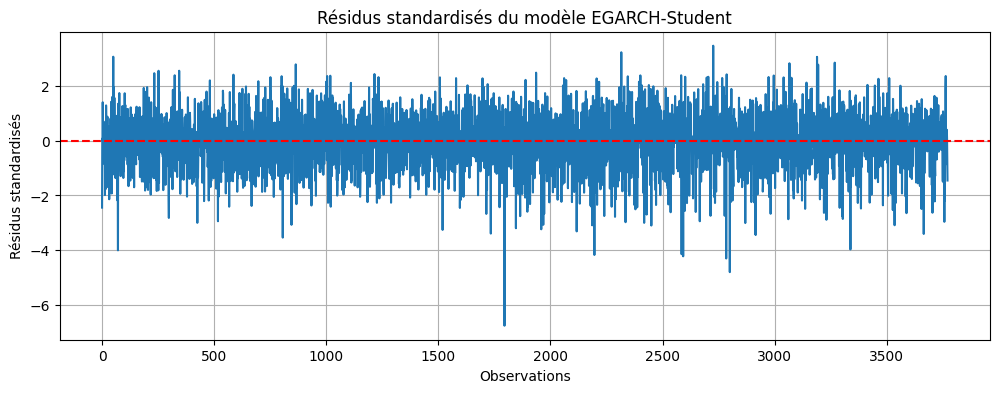

In [23]:

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Récupérer les résidus standardisés
residus = pd.Series(
    resultat_egarch_student.std_resid
).dropna()

# Test de Ljung-Box sur les résidus
test_lb = acorr_ljungbox(
    residus,
    lags=[10, 20],
    return_df=True
)

# Test de Ljung-Box sur les résidus au carré
test_lb_carre = acorr_ljungbox(
    residus**2,
    lags=[10, 20],
    return_df=True
)

# Test ARCH-LM
test_arch = het_arch(residus, nlags=10)

print("TEST LJUNG-BOX : RÉSIDUS")
display(test_lb)

print("\nTEST LJUNG-BOX : RÉSIDUS AU CARRÉ")
display(test_lb_carre)

print("\nTEST ARCH-LM")
print("Statistique :", round(test_arch[0], 4))
print("P-value :", round(test_arch[1], 6))

# Graphique des résidus standardisés
plt.figure(figsize=(12, 4))
plt.plot(residus)
plt.axhline(0, color="red", linestyle="--")
plt.title("Résidus standardisés du modèle EGARCH-Student")
plt.xlabel("Observations")
plt.ylabel("Résidus standardisés")
plt.grid(True)
plt.show()


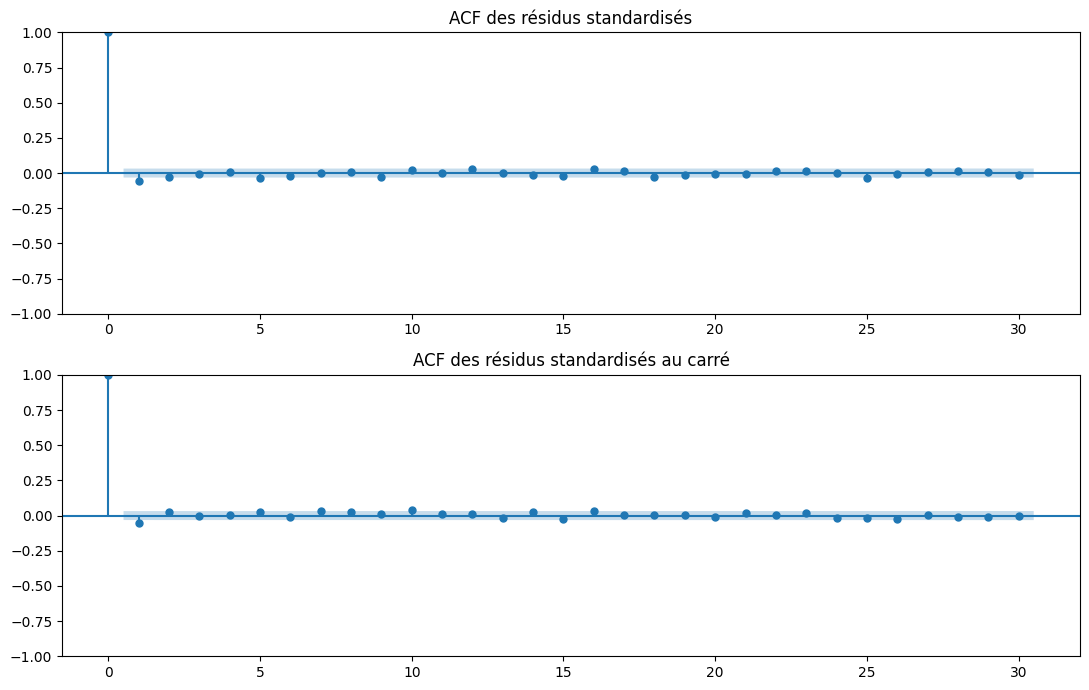

In [24]:

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

plot_acf(residus, lags=30, ax=axes[0])
axes[0].set_title("ACF des résidus standardisés")

plot_acf(residus**2, lags=30, ax=axes[1])
axes[1].set_title("ACF des résidus standardisés au carré")

plt.tight_layout()
plt.show()


In [25]:

# Vérifier les périodes disponibles

df["Date"] = pd.to_datetime(df["Date"])

print("Première date :", df["Date"].min())
print("Dernière date :", df["Date"].max())

print("\nNombre total d'observations :", len(df))

print("\nObservations de 2015 à 2025 :")
df_test = df[
    (df["Date"] >= "2015-01-01") &
    (df["Date"] <= "2025-12-31")
].copy()

print("Nombre d'observations :", len(df_test))
print("Première date de test :", df_test["Date"].min())
print("Dernière date de test :", df_test["Date"].max())


Première date : 2000-01-04 00:00:00
Dernière date : 2026-10-12 00:00:00

Nombre total d'observations : 6733

Observations de 2015 à 2025 :
Nombre d'observations : 2766
Première date de test : 2015-01-02 00:00:00
Dernière date de test : 2025-12-31 00:00:00


In [26]:

import numpy as np
import pandas as pd

# Trier les données par date
df = df.sort_values("Date").copy()

# Préparer les rendements du test
test = df[
    (df["Date"] >= "2015-01-01") &
    (df["Date"] <= "2025-12-31")
][["Date", "ret", "rv"]].copy()

# Retirer les valeurs manquantes
test = test.replace([np.inf, -np.inf], np.nan)
test = test.dropna(subset=["ret"])

print("Données de test préparées !")
print("Nombre d'observations :", len(test))
print("Première date :", test["Date"].min())
print("Dernière date :", test["Date"].max())

print("\nPremières observations :")
display(test.head())

print("\nValeurs manquantes :")
print(test.isna().sum())


Données de test préparées !
Nombre d'observations : 2766
Première date : 2015-01-02 00:00:00
Dernière date : 2025-12-31 00:00:00

Premières observations :


,Date,ret,rv
3772,2015-01-02,-0.034002,0.816434
3773,2015-01-05,-1.844721,0.593604
3774,2015-01-06,-0.893325,1.402789
3775,2015-01-07,1.156274,0.317339
3776,2015-01-08,1.773017,0.419266



Valeurs manquantes :
Date    0
ret     0
rv      0
dtype: int64


In [27]:

# Prévision de variance à un jour
# À partir du modèle GARCH-Student estimé sur 2000-2014

prevision = resultat_garch_student.forecast(
    horizon=1,
    reindex=False
)

variance_prevue = prevision.variance.iloc[-1, 0]

print("Prévision de variance :", round(variance_prevue, 6))
print("Unité : pourcentage au carré (%²)")

print(
    "Prévision de volatilité :",
    round(variance_prevue**0.5, 6),
    "%"
)

print(
    "Variance réalisée du premier jour de test :",
    round(test["rv"].iloc[0], 6)
)


Prévision de variance : 0.859754
Unité : pourcentage au carré (%²)
Prévision de volatilité : 0.927229 %
Variance réalisée du premier jour de test : 0.816434


In [28]:

# Comparaison de la première prévision
# avec la variance réalisée

variance_reelle = test["rv"].iloc[0]

erreur = variance_prevue - variance_reelle
erreur_carree = erreur**2

print("Variance prévue :", round(variance_prevue, 6))
print("Variance réalisée :", round(variance_reelle, 6))
print("Erreur de prévision :", round(erreur, 6))
print("Erreur quadratique :", round(erreur_carree, 6))


Variance prévue : 0.859754
Variance réalisée : 0.816434
Erreur de prévision : 0.04332
Erreur quadratique : 0.001877


In [29]:

# Vérifier les données disponibles pour l'évaluation

print("Nombre d'observations de test :", len(test))

print("\nPremières dates :")
print(test["Date"].head())

print("\nDernières dates :")
print(test["Date"].tail())

print("\nVérification des valeurs manquantes :")
print(test[["ret", "rv"]].isna().sum())

print("\nModèle utilisé :")
print(resultat_garch_student.model.volatility)


Nombre d'observations de test : 2766

Premières dates :
3772   2015-01-02
3773   2015-01-05
3774   2015-01-06
3775   2015-01-07
3776   2015-01-08
Name: Date, dtype: datetime64[ns]

Dernières dates :
6533   2025-12-24
6534   2025-12-26
6535   2025-12-29
6536   2025-12-30
6537   2025-12-31
Name: Date, dtype: datetime64[ns]

Vérification des valeurs manquantes :
ret    0
rv     0
dtype: int64

Modèle utilisé :
GARCH(p: 1, q: 1)


In [30]:

# Paramètres du modèle GARCH-Student

print("Paramètres estimés :")
print(resultat_garch_student.params)

print("\nNombre d'observations d'entraînement :")
print(len(rendements))

print("\nNombre d'observations de test :")
print(len(test))

print("\nDernières observations d'entraînement :")
print(rendements.tail())


Paramètres estimés :
mu          0.062401
omega       0.012336
alpha[1]    0.091174
beta[1]     0.902534
nu          7.625178
Name: params, dtype: float64

Nombre d'observations d'entraînement :
3772

Nombre d'observations de test :
2766

Dernières observations d'entraînement :
3767   -0.013931
3768    0.330411
3769    0.086140
3770   -0.490059
3771   -1.036438
Name: ret, dtype: float64


In [32]:

import numpy as np
import pandas as pd

# Récupérer les paramètres estimés
params = resultat_garch_student.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

# Récupérer la dernière variance conditionnelle
# de la période d'entraînement
variance_precedente = (
    resultat_garch_student.conditional_volatility.iloc[-1] ** 2
)

# Dernier rendement d'entraînement
rendement_precedent = rendements.iloc[-1]

# Prévisions journalières
previsions = []

for rendement_actuel in test["ret"]:

    residu_precedent = rendement_precedent - mu

    variance_actuelle = (
        omega
        + alpha * residu_precedent**2
        + beta * variance_precedente
    )

    previsions.append(variance_actuelle)

    # Actualisation après la journée observée
    variance_precedente = variance_actuelle
    rendement_precedent = rendement_actuel

# Ajouter les prévisions aux données de test
test = test.copy()
test["variance_prevue"] = previsions

print("Nombre de prévisions :", len(previsions))

print("\nPremières prévisions :")
print(test[["Date", "variance_prevue", "rv"]].head())

print("\nDernières prévisions :")
print(test[["Date", "variance_prevue", "rv"]].tail())


Nombre de prévisions : 2766

Premières prévisions :
           Date  variance_prevue        rv
3772 2015-01-02         0.859754  0.816434
3773 2015-01-05         0.789142  0.593604
3774 2015-01-06         1.056174  1.402789
3775 2015-01-07         1.048849  0.317339
3776 2015-01-08         1.068054  0.419266

Dernières prévisions :
           Date  variance_prevue        rv
6533 2025-12-24         0.578599  0.050196
6534 2025-12-26         0.540669  0.057786
6535 2025-12-29         0.501094  0.103371
6536 2025-12-30         0.480084  0.039616
6537 2025-12-31         0.449278  0.109787


In [33]:

import numpy as np

# Variances réalisées et prévues
rv = test["rv"].to_numpy()
vp = test["variance_prevue"].to_numpy()

# Vérifier les valeurs
assert np.all(np.isfinite(rv))
assert np.all(np.isfinite(vp))
assert np.all(vp > 0)
assert np.all(rv >= 0)

# Calcul du RMSE
rmse = np.sqrt(np.mean((rv - vp)**2))

# Calcul du QLIKE
qlike = np.mean(np.log(vp) + rv / vp)

print("ÉVALUATION HORS ÉCHANTILLON")
print("Modèle : GARCH(1,1) - Student")
print("Nombre de prévisions :", len(vp))
print("RMSE :", round(rmse, 6))
print("QLIKE :", round(qlike, 6))


ÉVALUATION HORS ÉCHANTILLON
Modèle : GARCH(1,1) - Student
Nombre de prévisions : 2766
RMSE : 2.240914
QLIKE : 0.332755


In [34]:

import pandas as pd

# Tableau des performances hors échantillon
resultats_hors_echantillon = pd.DataFrame({
    "Modèle": ["GARCH - Student"],
    "RMSE": [rmse],
    "QLIKE": [qlike],
    "Observations": [len(test)]
})

display(resultats_hors_echantillon.round(6))


,Modèle,RMSE,QLIKE,Observations
0,GARCH - Student,2.240914,0.332755,2766


In [35]:

# Vérifier les modèles disponibles dans Colab

modeles = [
    "resultat_garch",
    "resultat_garch_student",
    "resultat_gjr_normal",
    "resultat_gjr_student",
    "resultat_egarch_normal",
    "resultat_egarch_student"
]

for nom in modeles:
    if nom in globals():
        print("Disponible :", nom)
    else:
        print("Non trouvé :", nom)


Disponible : resultat_garch
Disponible : resultat_garch_student
Disponible : resultat_gjr_normal
Disponible : resultat_gjr_student
Disponible : resultat_egarch_normal
Disponible : resultat_egarch_student


In [36]:

# GARCH(1,1) - Distribution normale
# Récupérer les paramètres estimés sur 2000-2014

params = resultat_garch.params

print("PARAMÈTRES GARCH - NORMALE")
print(params)

print("\nPériode de test :")
print("Observations :", len(test))
print("Début :", test["Date"].min())
print("Fin :", test["Date"].max())

# Vérifier la présence des paramètres nécessaires
for nom in ["mu", "omega", "alpha[1]", "beta[1]"]:
    print(nom, ":", nom in params.index)


PARAMÈTRES GARCH - NORMALE
mu          0.048832
omega       0.016710
alpha[1]    0.092904
beta[1]     0.895139
Name: params, dtype: float64

Période de test :
Observations : 2766
Début : 2015-01-02 00:00:00
Fin : 2025-12-31 00:00:00
mu : True
omega : True
alpha[1] : True
beta[1] : True


In [37]:

import numpy as np

# Paramètres GARCH - Normale
mu = resultat_garch.params["mu"]
omega = resultat_garch.params["omega"]
alpha = resultat_garch.params["alpha[1]"]
beta = resultat_garch.params["beta[1]"]

# Dernière variance conditionnelle estimée
variance_precedente = float(
    resultat_garch.conditional_volatility.iloc[-1]**2
)

# Dernier résidu de la période d'entraînement
rendement_precedent = float(rendements.iloc[-1])
residu_precedent = rendement_precedent - mu

# Prévisions à un jour, sans réestimation
previsions_normale = []

for rendement_actuel in test["ret"]:
    variance_actuelle = (
        omega
        + alpha * residu_precedent**2
        + beta * variance_precedente
    )

    previsions_normale.append(variance_actuelle)

    # Actualiser après observation du rendement
    variance_precedente = variance_actuelle
    residu_precedent = float(rendement_actuel) - mu

# Ajouter les prévisions au tableau de test
test["variance_prevue_normale"] = previsions_normale

print("PRÉVISIONS GARCH - NORMALE")
print("Nombre de prévisions :", len(previsions_normale))

display(
    test[["Date", "variance_prevue_normale", "rv"]].head()
)


PRÉVISIONS GARCH - NORMALE
Nombre de prévisions : 2766


,Date,variance_prevue_normale,rv
3772,2015-01-02,0.852673,0.816434
3773,2015-01-05,0.780609,0.593604
3774,2015-01-06,1.048576,1.402789
3775,2015-01-07,1.037799,0.317339
3776,2015-01-08,1.059625,0.419266


In [38]:

import numpy as np

# Variances réalisées
rv_normale = test["rv"].to_numpy()

# Variances prévues par GARCH - Normale
vp_normale = test["variance_prevue_normale"].to_numpy()

# Vérifier les données
assert np.all(np.isfinite(rv_normale))
assert np.all(np.isfinite(vp_normale))
assert np.all(vp_normale > 0)
assert np.all(rv_normale >= 0)

# Calcul du RMSE
rmse_normale = np.sqrt(
    np.mean((rv_normale - vp_normale)**2)
)

# Calcul du QLIKE
qlike_normale = np.mean(
    np.log(vp_normale) + rv_normale / vp_normale
)

print("ÉVALUATION HORS ÉCHANTILLON")
print("Modèle : GARCH(1,1) - Normale")
print("Nombre de prévisions :", len(vp_normale))
print("RMSE :", round(rmse_normale, 6))
print("QLIKE :", round(qlike_normale, 6))


ÉVALUATION HORS ÉCHANTILLON
Modèle : GARCH(1,1) - Normale
Nombre de prévisions : 2766
RMSE : 2.136382
QLIKE : 0.333286


In [39]:

import pandas as pd

comparaison_hors_echantillon = pd.DataFrame({
    "Modèle": [
        "GARCH - Normale",
        "GARCH - Student"
    ],
    "RMSE": [
        rmse_normale,
        rmse
    ],
    "QLIKE": [
        qlike_normale,
        qlike
    ],
    "Observations": [
        len(test),
        len(test)
    ]
})

print("COMPARAISON HORS ÉCHANTILLON")
display(comparaison_hors_echantillon.round(6))

print("\nMeilleur modèle selon le RMSE :")
print(
    comparaison_hors_echantillon.loc[
        comparaison_hors_echantillon["RMSE"].idxmin(),
        "Modèle"
    ]
)

print("\nMeilleur modèle selon le QLIKE :")
print(
    comparaison_hors_echantillon.loc[
        comparaison_hors_echantillon["QLIKE"].idxmin(),
        "Modèle"
    ]
)


COMPARAISON HORS ÉCHANTILLON


,Modèle,RMSE,QLIKE,Observations
0,GARCH - Normale,2.136382,0.333286,2766
1,GARCH - Student,2.240914,0.332755,2766



Meilleur modèle selon le RMSE :
GARCH - Normale

Meilleur modèle selon le QLIKE :
GARCH - Student


In [40]:

# Étape 5 : GJR-GARCH - Normale

params_gjr = resultat_gjr_normal.params

print("PARAMÈTRES GJR-GARCH - NORMALE")
print(params_gjr)

print("\nDernière variance conditionnelle :")
print(
    resultat_gjr_normal.conditional_volatility.iloc[-1]**2
)

print("\nNombre d'observations de test :")
print(len(test))


PARAMÈTRES GJR-GARCH - NORMALE
mu          9.018302e-03
omega       1.853933e-02
alpha[1]    1.589249e-14
gamma[1]    1.625076e-01
beta[1]     9.026130e-01
Name: params, dtype: float64

Dernière variance conditionnelle :
0.6034957933456406

Nombre d'observations de test :
2766


In [41]:

import numpy as np

# Paramètres estimés du GJR-GARCH
p = resultat_gjr_normal.params

mu = p["mu"]
omega = p["omega"]
alpha = p["alpha[1]"]
gamma = p["gamma[1]"]
beta = p["beta[1]"]

# Initialisation à la fin de l'entraînement
variance_precedente = float(
    resultat_gjr_normal.conditional_volatility.iloc[-1]**2
)

residu_precedent = float(
    rendements.iloc[-1] - mu
)

previsions_gjr_normale = []

# Prévisions à un jour, sans réestimation
for rendement_actuel in test["ret"]:

    variance_actuelle = (
        omega
        + alpha * residu_precedent**2
        + gamma * residu_precedent**2
          * (residu_precedent < 0)
        + beta * variance_precedente
    )

    previsions_gjr_normale.append(variance_actuelle)

    variance_precedente = variance_actuelle
    residu_precedent = float(rendement_actuel - mu)

# Ajouter les prévisions au tableau
test["variance_prevue_gjr_normale"] = previsions_gjr_normale

print("PRÉVISIONS GJR-GARCH - NORMALE")
print("Nombre de prévisions :", len(previsions_gjr_normale))

display(
    test[["Date", "variance_prevue_gjr_normale", "rv"]].head()
)


PRÉVISIONS GJR-GARCH - NORMALE
Nombre de prévisions : 2766


,Date,variance_prevue_gjr_normale,rv
3772,2015-01-02,0.740880,0.816434
3773,2015-01-05,0.687568,0.593604
3774,2015-01-06,1.197580,1.402789
3775,2015-01-07,1.231808,0.317339
3776,2015-01-08,1.130386,0.419266


In [42]:

import numpy as np

# Variances réalisées
rv_gjr = test["rv"].to_numpy()

# Variances prévues par GJR-GARCH normale
vp_gjr = test["variance_prevue_gjr_normale"].to_numpy()

# Vérification des données
assert np.all(np.isfinite(rv_gjr))
assert np.all(np.isfinite(vp_gjr))
assert np.all(rv_gjr >= 0)
assert np.all(vp_gjr > 0)

# Calcul du RMSE
rmse_gjr_normale = np.sqrt(
    np.mean((rv_gjr - vp_gjr)**2)
)

# Calcul du QLIKE
qlike_gjr_normale = np.mean(
    np.log(vp_gjr) + rv_gjr / vp_gjr
)

print("ÉVALUATION HORS ÉCHANTILLON")
print("Modèle : GJR-GARCH - Normale")
print("Nombre de prévisions :", len(vp_gjr))
print("RMSE :", round(rmse_gjr_normale, 6))
print("QLIKE :", round(qlike_gjr_normale, 6))


ÉVALUATION HORS ÉCHANTILLON
Modèle : GJR-GARCH - Normale
Nombre de prévisions : 2766
RMSE : 2.324675
QLIKE : 0.291856


In [43]:

import numpy as np

# Paramètres du modèle GJR-GARCH Student
p = resultat_gjr_student.params

mu = float(p["mu"])
omega = float(p["omega"])
alpha = float(p["alpha[1]"])
gamma = float(p["gamma[1]"])
beta = float(p["beta[1]"])

# Initialisation à la fin de l'entraînement
variance_precedente = float(
    resultat_gjr_student.conditional_volatility.iloc[-1]**2
)

residu_precedent = float(rendements.iloc[-1] - mu)

previsions_gjr_student = []

# Prévisions à un jour
for rendement_actuel in test["ret"]:

    variance_actuelle = (
        omega
        + alpha * residu_precedent**2
        + gamma * residu_precedent**2
          * (residu_precedent < 0)
        + beta * variance_precedente
    )

    previsions_gjr_student.append(variance_actuelle)

    variance_precedente = variance_actuelle
    residu_precedent = float(rendement_actuel - mu)

# Ajouter les prévisions
test["variance_prevue_gjr_student"] = previsions_gjr_student

# Calculer les indicateurs
rv = test["rv"].to_numpy()
vp = test["variance_prevue_gjr_student"].to_numpy()

assert np.all(np.isfinite(vp))
assert np.all(vp > 0)

rmse_gjr_student = np.sqrt(np.mean((rv - vp)**2))
qlike_gjr_student = np.mean(np.log(vp) + rv / vp)

print("GJR-GARCH – STUDENT")
print("Nombre de prévisions :", len(vp))
print("RMSE :", round(rmse_gjr_student, 6))
print("QLIKE :", round(qlike_gjr_student, 6))

display(
    test[["Date", "variance_prevue_gjr_student", "rv"]].head()
)


GJR-GARCH – STUDENT
Nombre de prévisions : 2766
RMSE : 2.421091
QLIKE : 0.289247


,Date,variance_prevue_gjr_student,rv
3772,2015-01-02,0.744362,0.816434
3773,2015-01-05,0.689054,0.593604
3774,2015-01-06,1.212696,1.402789
3775,2015-01-07,1.251729,0.317339
3776,2015-01-08,1.147779,0.419266


In [44]:

# Vérifier les paramètres des deux modèles EGARCH

print("=== EGARCH NORMALE ===")
print(resultat_egarch_normal.params)

print("\n=== EGARCH STUDENT ===")
print(resultat_egarch_student.params)

print("\n=== CONFIGURATION DES MODÈLES ===")
print("Normale :", resultat_egarch_normal.model.volatility)
print("Student :", resultat_egarch_student.model.volatility)

print("\n=== CONVERGENCE ===")
print("Normale :", resultat_egarch_normal.convergence_flag)
print("Student :", resultat_egarch_student.convergence_flag)


=== EGARCH NORMALE ===
mu          0.009790
omega       0.001845
alpha[1]    0.110731
gamma[1]   -0.142721
beta[1]     0.979647
Name: params, dtype: float64

=== EGARCH STUDENT ===
mu          0.031780
omega      -0.001821
alpha[1]    0.101343
gamma[1]   -0.150421
beta[1]     0.984729
nu          8.648735
Name: params, dtype: float64

=== CONFIGURATION DES MODÈLES ===
Normale : EGARCH(p: 1, o: 1, q: 1)
Student : EGARCH(p: 1, o: 1, q: 1)

=== CONVERGENCE ===
Normale : 0
Student : 0


In [45]:

import numpy as np
import pandas as pd

def previsions_egarch(resultat, rendements, test):
    p = resultat.params

    mu = float(p["mu"])
    omega = float(p["omega"])
    alpha = float(p["alpha[1]"])
    gamma = float(p["gamma[1]"])
    beta = float(p["beta[1]"])

    # Espérance de la valeur absolue du choc
    # standardisé selon la distribution estimée
    distribution = resultat.model.distribution
    parametres_distribution = np.asarray(
        [p[nom] for nom in distribution.parameter_names()],
        dtype=float
    )

    e_abs_z = distribution.moment(
        1.0,
        parameters=parametres_distribution
    ) if False else None

    # E|Z| par simulation reproductible
    simulateur = distribution.simulate(
        parametres_distribution
    )
    np.random.seed(123)
    z_simules = simulateur(1000000)
    e_abs_z = np.mean(np.abs(z_simules))

    # Dernier état d'entraînement
    variance_precedente = float(
        resultat.conditional_volatility.iloc[-1]**2
    )
    residu_precedent = float(
        rendements.iloc[-1] - mu
    )

    previsions = []

    for rendement in test["ret"]:
        z_precedent = (
            residu_precedent /
            np.sqrt(variance_precedente)
        )

        log_variance = (
            omega
            + beta * np.log(variance_precedente)
            + alpha * (abs(z_precedent) - e_abs_z)
            + gamma * z_precedent
        )

        variance_actuelle = np.exp(log_variance)
        previsions.append(variance_actuelle)

        variance_precedente = variance_actuelle
        residu_precedent = float(rendement - mu)

    return np.asarray(previsions)


# Prévisions EGARCH normale
test["variance_prevue_egarch_normale"] = previsions_egarch(
    resultat_egarch_normal, rendements, test
)

# Prévisions EGARCH Student
test["variance_prevue_egarch_student"] = previsions_egarch(
    resultat_egarch_student, rendements, test
)

print("PRÉVISIONS EGARCH TERMINÉES")
print("Nombre d'observations :", len(test))

display(
    test[[
        "Date",
        "variance_prevue_egarch_normale",
        "variance_prevue_egarch_student",
        "rv"
    ]].head()
)


PRÉVISIONS EGARCH TERMINÉES
Nombre d'observations : 2766


,Date,variance_prevue_egarch_normale,variance_prevue_egarch_student,rv
3772,2015-01-02,0.744667,0.726194,0.816434
3773,2015-01-05,0.695981,0.687020,0.593604
3774,2015-01-06,1.129617,1.128108,1.402789
3775,2015-01-07,1.281824,1.294613,0.317339
3776,2015-01-08,1.132423,1.134272,0.419266


In [46]:

import numpy as np
import pandas as pd

# Variance réalisée
rv = test["rv"].to_numpy()

# Fonction de calcul des indicateurs
def evaluer_modele(colonne):
    vp = test[colonne].to_numpy()

    assert np.all(np.isfinite(vp))
    assert np.all(vp > 0)
    assert np.all(np.isfinite(rv))
    assert np.all(rv >= 0)

    rmse = np.sqrt(np.mean((rv - vp)**2))
    qlike = np.mean(np.log(vp) + rv / vp)

    return rmse, qlike

# EGARCH normale
rmse_egarch_normal, qlike_egarch_normal = evaluer_modele(
    "variance_prevue_egarch_normale"
)

# EGARCH Student
rmse_egarch_student, qlike_egarch_student = evaluer_modele(
    "variance_prevue_egarch_student"
)

print("ÉVALUATION EGARCH - NORMALE")
print("RMSE :", round(rmse_egarch_normal, 6))
print("QLIKE :", round(qlike_egarch_normal, 6))

print("\nÉVALUATION EGARCH - STUDENT")
print("RMSE :", round(rmse_egarch_student, 6))
print("QLIKE :", round(qlike_egarch_student, 6))


ÉVALUATION EGARCH - NORMALE
RMSE : 1.505654
QLIKE : 0.268385

ÉVALUATION EGARCH - STUDENT
RMSE : 1.697915
QLIKE : 0.292732


In [47]:

import pandas as pd

# Comparaison des six modèles
comparaison_finale = pd.DataFrame({
    "Modèle": [
        "GARCH - Normale",
        "GARCH - Student",
        "GJR-GARCH - Normale",
        "GJR-GARCH - Student",
        "EGARCH - Normale",
        "EGARCH - Student"
    ],
    "RMSE": [
        rmse_normale,
        rmse,
        rmse_gjr_normale,
        rmse_gjr_student,
        rmse_egarch_normal,
        rmse_egarch_student
    ],
    "QLIKE": [
        qlike_normale,
        qlike,
        qlike_gjr_normale,
        qlike_gjr_student,
        qlike_egarch_normal,
        qlike_egarch_student
    ]
})

display(comparaison_finale.round(6))

print("Meilleur modèle selon le RMSE :")
print(comparaison_finale.loc[
    comparaison_finale["RMSE"].idxmin(), "Modèle"
])

print("\nMeilleur modèle selon le QLIKE :")
print(comparaison_finale.loc[
    comparaison_finale["QLIKE"].idxmin(), "Modèle"
])


,Modèle,RMSE,QLIKE
0,GARCH - Normale,2.136382,0.333286
1,GARCH - Student,2.240914,0.332755
2,GJR-GARCH - Normale,2.324675,0.291856
3,GJR-GARCH - Student,2.421091,0.289247
4,EGARCH - Normale,1.505654,0.268385
5,EGARCH - Student,1.697915,0.292732


Meilleur modèle selon le RMSE :
EGARCH - Normale

Meilleur modèle selon le QLIKE :
EGARCH - Normale


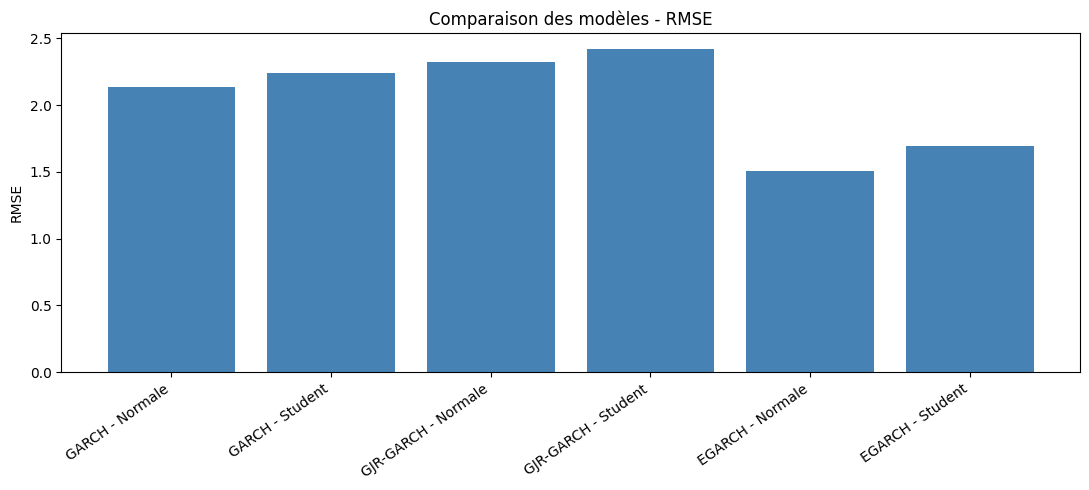

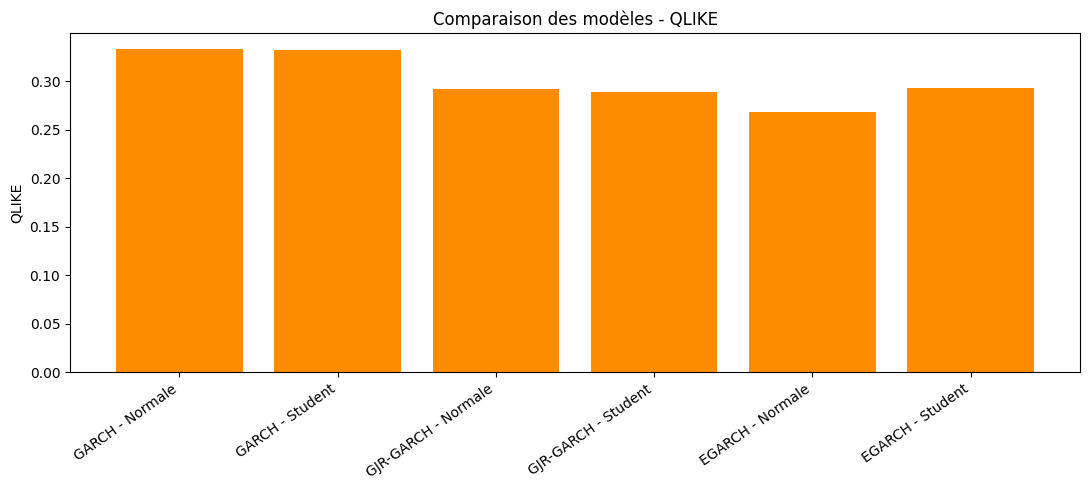

In [48]:

import matplotlib.pyplot as plt

# Graphique 1 : Comparaison du RMSE
plt.figure(figsize=(11, 5))

plt.bar(
    comparaison_finale["Modèle"],
    comparaison_finale["RMSE"],
    color="steelblue"
)

plt.title("Comparaison des modèles - RMSE")
plt.ylabel("RMSE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Graphique 2 : Comparaison du QLIKE
plt.figure(figsize=(11, 5))

plt.bar(
    comparaison_finale["Modèle"],
    comparaison_finale["QLIKE"],
    color="darkorange"
)

plt.title("Comparaison des modèles - QLIKE")
plt.ylabel("QLIKE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [49]:

# Vérification des prévisions EGARCH

import inspect

print("=== FONCTION DE PRÉVISION EGARCH ===")

# Rechercher les fonctions de prévision disponibles
for nom, objet in list(globals().items()):
    if callable(objet) and "egarch" in nom.lower():
        print("\nFonction :", nom)
        try:
            print(inspect.getsource(objet))
        except (OSError, TypeError):
            print("Code source non disponible")

print("\n=== PREMIÈRES PRÉVISIONS ===")

display(test[[
    "Date",
    "variance_prevue_egarch_normale",
    "variance_prevue_egarch_student",
    "rv"
]].head())


=== FONCTION DE PRÉVISION EGARCH ===

Fonction : previsions_egarch
def previsions_egarch(resultat, rendements, test):
    p = resultat.params

    mu = float(p["mu"])
    omega = float(p["omega"])
    alpha = float(p["alpha[1]"])
    gamma = float(p["gamma[1]"])
    beta = float(p["beta[1]"])

    # Espérance de la valeur absolue du choc
    # standardisé selon la distribution estimée
    distribution = resultat.model.distribution
    parametres_distribution = np.asarray(
        [p[nom] for nom in distribution.parameter_names()],
        dtype=float
    )

    e_abs_z = distribution.moment(
        1.0,
        parameters=parametres_distribution
    ) if False else None

    # E|Z| par simulation reproductible
    simulateur = distribution.simulate(
        parametres_distribution
    )
    np.random.seed(123)
    z_simules = simulateur(1000000)
    e_abs_z = np.mean(np.abs(z_simules))

    # Dernier état d'entraînement
    variance_precedente = float(
        resultat.conditional_vol

,Date,variance_prevue_egarch_normale,variance_prevue_egarch_student,rv
3772,2015-01-02,0.744667,0.726194,0.816434
3773,2015-01-05,0.695981,0.687020,0.593604
3774,2015-01-06,1.129617,1.128108,1.402789
3775,2015-01-07,1.281824,1.294613,0.317339
3776,2015-01-08,1.132423,1.134272,0.419266


In [50]:

# Vérification finale des données et des résultats

print("=== VÉRIFICATION FINALE ===")

print("\nNombre d'observations de test :")
print(len(test))

print("\nValeurs manquantes :")
colonnes = [
    "rv",
    "variance_prevue_egarch_normale",
    "variance_prevue_egarch_student"
]
print(test[colonnes].isna().sum())

print("\nConvergence des modèles EGARCH :")
print("Normale :", resultat_egarch_normal.convergence_flag)
print("Student :", resultat_egarch_student.convergence_flag)

print("\nMeilleur modèle selon le RMSE :")
print(comparaison_finale.loc[
    comparaison_finale["RMSE"].idxmin(), "Modèle"
])

print("\nMeilleur modèle selon le QLIKE :")
print(comparaison_finale.loc[
    comparaison_finale["QLIKE"].idxmin(), "Modèle"
])


=== VÉRIFICATION FINALE ===

Nombre d'observations de test :
2766

Valeurs manquantes :
rv                                0
variance_prevue_egarch_normale    0
variance_prevue_egarch_student    0
dtype: int64

Convergence des modèles EGARCH :
Normale : 0
Student : 0

Meilleur modèle selon le RMSE :
EGARCH - Normale

Meilleur modèle selon le QLIKE :
EGARCH - Normale


Interprétation des résultats hors échantillon

L’étude compare six modèles de volatilité : GARCH(1,1), GJR-GARCH(1,1) et EGARCH(1,1), chacun estimé avec une distribution normale et une distribution Student.

Les modèles sont estimés sur la période 2000–2014 et évalués sur 2 766 observations hors échantillon couvrant la période 2015–2025.

Les performances prévisionnelles sont comparées à l’aide de deux indicateurs : le RMSE (Root Mean Squared Error) et le QLIKE (Quasi-Likelihood Loss). Pour ces deux indicateurs, une valeur plus faible indique une meilleure performance.

Selon les résultats obtenus, le modèle EGARCH(1,1) avec distribution normale présente les meilleures performances, avec un RMSE de 1,505654 et un QLIKE de 0,268385.

Ce résultat suggère que la prise en compte de l’asymétrie des réactions de la volatilité aux chocs financiers améliore la qualité des prévisions pour les données étudiées.

Par ailleurs, l’utilisation d’une distribution Student ne conduit pas systématiquement à de meilleures prévisions que la distribution normale.

Ces conclusions sont provisoires et supposent que les prévisions ont été produites sans utilisation d’informations futures et que les modèles ont été évalués selon une méthodologie comparable.

In [51]:

import inspect

print("=== CODE COMPLET DE LA FONCTION EGARCH ===")

for nom, objet in list(globals().items()):
    if inspect.isfunction(objet) and "egarch" in nom.lower():
        print("\nFonction :", nom)
        try:
            print(inspect.getsource(objet))
        except (OSError, TypeError):
            print("Source non disponible")

print("\n=== FIN DE VÉRIFICATION ===")


=== CODE COMPLET DE LA FONCTION EGARCH ===

Fonction : previsions_egarch
def previsions_egarch(resultat, rendements, test):
    p = resultat.params

    mu = float(p["mu"])
    omega = float(p["omega"])
    alpha = float(p["alpha[1]"])
    gamma = float(p["gamma[1]"])
    beta = float(p["beta[1]"])

    # Espérance de la valeur absolue du choc
    # standardisé selon la distribution estimée
    distribution = resultat.model.distribution
    parametres_distribution = np.asarray(
        [p[nom] for nom in distribution.parameter_names()],
        dtype=float
    )

    e_abs_z = distribution.moment(
        1.0,
        parameters=parametres_distribution
    ) if False else None

    # E|Z| par simulation reproductible
    simulateur = distribution.simulate(
        parametres_distribution
    )
    np.random.seed(123)
    z_simules = simulateur(1000000)
    e_abs_z = np.mean(np.abs(z_simules))

    # Dernier état d'entraînement
    variance_precedente = float(
        resultat.condition

In [53]:

print("=== VÉRIFICATION DES PÉRIODES ===")

print("Observations d'entraînement :", len(rendements))
print("Observations de test :", len(test))

print("\nPremière date de test :")
print(test["Date"].min())

print("\nDernière date de test :")
print(test["Date"].max())

print("\nTotal des observations :")
print(len(rendements) + len(test))


=== VÉRIFICATION DES PÉRIODES ===
Observations d'entraînement : 3772
Observations de test : 2766

Première date de test :
2015-01-02 00:00:00

Dernière date de test :
2025-12-31 00:00:00

Total des observations :
6538
